# TimeSeries Mooring Data - Quick Plot

From an erddap Dataset, specify the Mooring ID to get a quick plot of the data

In [1]:
from erddapy import ERDDAP
import pandas as pd
import numpy as np

In [2]:
server_url = 'http://ecofoci-field.pmel.noaa.gov:8082/erddap'
dataset_name = 'TEST_All_SUNAs_Aggregate'
e = ERDDAP(server=server_url,
          protocol='tabledap',
          response='csv')

e.dataset_id=dataset_name

pdf = e.to_pandas(
            index_col='time (UTC)',
            parse_dates=True,
            skiprows=(1,)  # units information can be dropped.
        )
# pdf

In [11]:
pdf = pdf[pdf["timeseries_id"].str.contains("8a")]

In [21]:
pdf

,pressure (meter),latitude (degrees_north),longitude (degrees_east),temperature (degree_C),gas_pressure (mbar),absorbance_254nm (uM),absorbance_350nm (uM),nitrate (uM),mooring_id,timeseries_id,Instrument_Identifier,Water_Depth (dbar)
time (UTC),,,,,,,,,,,,
2020-10-13 23:00:00+00:00,30.0,NaN,NaN,NaN,NaN,NaN,NaN,0.555230,NaN,20bsv8a_suna_0030m,NaN,NaN
2020-10-14 01:00:00+00:00,30.0,NaN,NaN,NaN,NaN,NaN,NaN,2.083140,NaN,20bsv8a_suna_0030m,NaN,NaN
2020-10-14 23:00:00+00:00,30.0,NaN,NaN,NaN,NaN,NaN,NaN,1.353570,NaN,20bsv8a_suna_0030m,NaN,NaN
2020-10-15 00:00:00+00:00,30.0,NaN,NaN,NaN,NaN,NaN,NaN,1.209491,NaN,20bsv8a_suna_0030m,NaN,NaN
2020-10-15 01:00:00+00:00,30.0,NaN,NaN,NaN,NaN,NaN,NaN,0.110899,NaN,20bsv8a_suna_0030m,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...
2025-08-14 13:00:00+00:00,55.0,NaN,NaN,NaN,NaN,NaN,NaN,13.580929,NaN,24bs8a_suna_0054m,NaN,NaN
2025-08-14 14:00:00+00:00,55.0,NaN,NaN,NaN,NaN,NaN,NaN,13.601162,NaN,24bs8a_suna_0054m,NaN,NaN
2025-08-14 15:00:00+00:00,55.0,NaN,NaN,NaN,NaN,NaN,NaN,13.596107,NaN,24bs8a_suna_0054m,NaN,NaN


In [24]:
%matplotlib inline
import datetime
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.dates import YearLocator, WeekdayLocator, MonthLocator, DayLocator, HourLocator, DateFormatter
import matplotlib.ticker as ticker

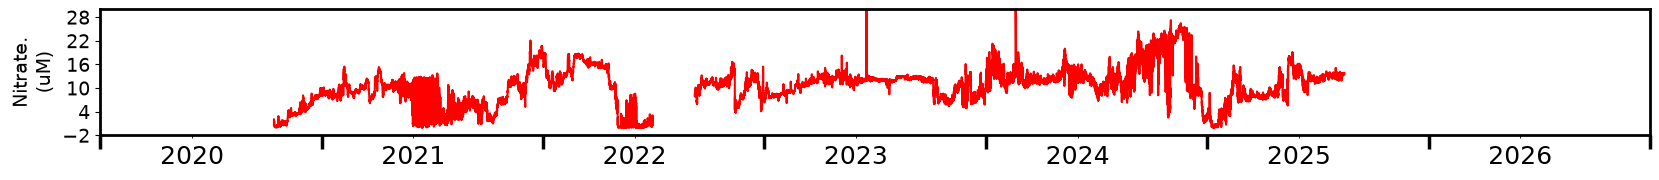

In [46]:
fig, ax = plt.subplots(1,figsize=(20, 2))

# ax[0].scatter(htcon_anom.time,htcon_anom,s=10,c=htcon_anom, cmap=cm.cm.balance)

# for year in icedf.drop(['day_of_year'],axis=1).columns:
#     ax[1].plot([datetime.datetime.strptime(f'{year} {x}','%Y %j') for x in icedf.day_of_year], icedf[year],c=(120/255,23/255,154/255),alpha=0.75)
for g,gr in pdf.groupby('pressure (meter)'):
    if gr['pressure (meter)'].iloc[0] == pdf['pressure (meter)'].max():
        plt.plot(gr.index,gr['nitrate (uM)'],color='r')
    if gr['pressure (meter)'].iloc[0] == pdf['pressure (meter)'].min():
        plt.plot(gr.index,gr['nitrate (uM)'],color='r')
ax.set_ylabel('Nitrate.\n(uM)',fontsize=14)

[x.set_linewidth(2.0) for x in ax.spines.values()]
ax.set_xlim([datetime.date(2020,1,1),datetime.date(2027,1,1)])
ax.set_ylim([-1,30])

ax.yaxis.set_ticks(range(-2,30,6))
ax.xaxis.set_major_locator(MonthLocator(bymonthday=1,interval=12))
ax.xaxis.set_minor_locator(MonthLocator(bymonth=6))
ax.xaxis.set_minor_formatter(DateFormatter('%Y'))
ax.xaxis.set_major_formatter(DateFormatter(''))
ax.yaxis.set_tick_params(which='major',labelsize=14)
ax.xaxis.set_tick_params(which='major', pad=3,labelsize=14, width=2.5, length=10)
ax.xaxis.set_tick_params(which='minor', pad=5,labelsize=18)

plt.subplots_adjust(bottom=0.25)

fig.savefig(f'{dataset_name}.png')